# DataVisualisation-TP2025 — TP1

[Teacher assignment](https://github.com/ahmed3991/DataVisualisation-TP2025/blob/main/TP1/TP1.md)

Run the cells from top to bottom. The required answers appear at the end. The repository also contains `EXPLICATION_AR.md` with the complete Arabic explanation. Data are included locally or downloaded from their original sources.

## Install the required libraries if needed

In [1]:
import importlib.util
import subprocess
import sys
packages = {'numpy': 'numpy', 'pandas': 'pandas', 'matplotlib': 'matplotlib'}
missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])


## 1. Imports and data source

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd

ROOT = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
DATA = ROOT / "data" / "georgia_cumulative_cases.csv"
OUT = ROOT / "results"
OUT.mkdir(parents=True, exist_ok=True)
SOURCE_URL = "https://static.usafacts.org/public/data/covid-19/covid_confirmed_usafacts.csv"

## 2. Load actual USAFacts Georgia data and calculate daily cases

In [3]:
if DATA.exists():
    georgia = pd.read_csv(DATA, parse_dates=["date"])
else:
    source = pd.read_csv(SOURCE_URL)
    counties = source.loc[source["State"] == "GA"]
    # Include the statewide unallocated row as well as the 159 counties.
    date_columns = source.columns[4:]
    totals = counties[date_columns].sum(axis=0)
    georgia = pd.DataFrame({"date": pd.to_datetime(date_columns),
                            "confirmed_cases": totals.to_numpy()})
    DATA.parent.mkdir(parents=True, exist_ok=True)
    georgia.to_csv(DATA, index=False)

georgia = georgia.sort_values("date")
georgia["daily_new_cases"] = georgia["confirmed_cases"].diff()
# Compute the rolling average BEFORE filtering May, retaining April history.
georgia["rolling_7_days"] = georgia["daily_new_cases"].rolling(7).mean()
may = georgia.loc[georgia["date"].between("2020-05-01", "2020-05-31")].copy()
print(may.head().to_string(index=False))
may.to_csv(OUT / "may_2020_cases.csv", index=False)

      date  confirmed_cases  daily_new_cases  rolling_7_days
2020-05-01            26805            973.0      684.428571
2020-05-02            27627            822.0      723.000000
2020-05-03            27928            301.0      728.285714
2020-05-04            28709            781.0      731.000000
2020-05-05            29196            487.0      711.285714


## 3. Exploratory plot: chronological raw daily cases

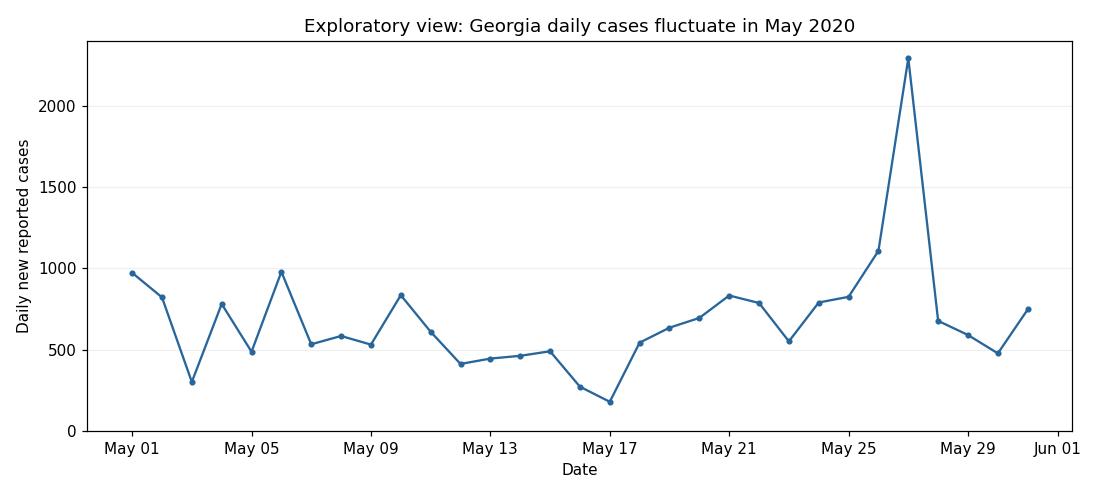

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(may["date"], may["daily_new_cases"], marker="o", markersize=3, color="#27659a")
ax.set(title="Exploratory view: Georgia daily cases fluctuate in May 2020",
       xlabel="Date", ylabel="Daily new reported cases")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.grid(axis="y", alpha=0.2)
ax.set_ylim(bottom=min(0, may["daily_new_cases"].min()))
fig.tight_layout()
fig.savefig(OUT / "01_exploratory.png", dpi=140)
plt.show()
plt.close(fig)

## 4. Educational misleading recreation: sort dates by case count

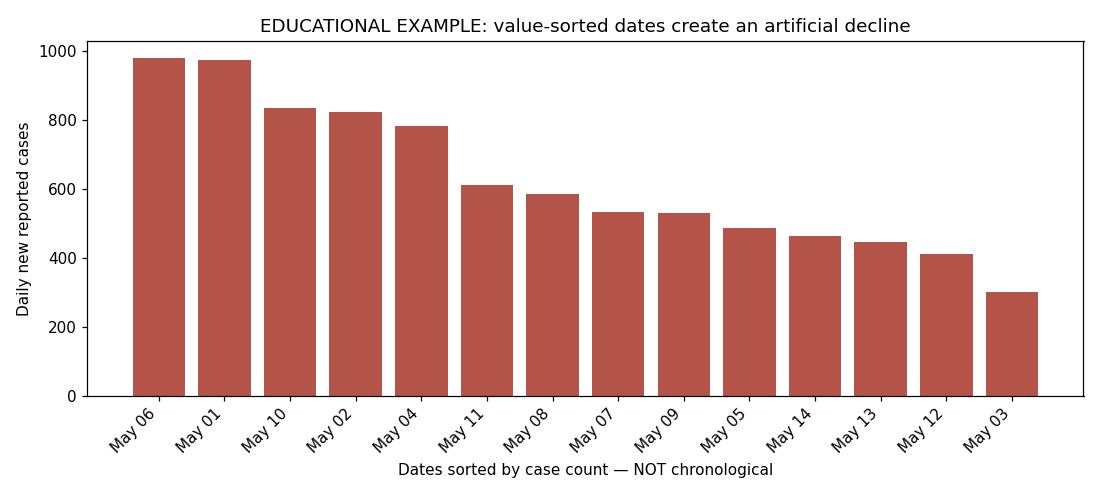

In [5]:
segment = may.loc[may["date"].between("2020-05-01", "2020-05-14")]
misleading = segment.sort_values("daily_new_cases", ascending=False)
fig, ax = plt.subplots(figsize=(10, 4.5))
positions = np.arange(len(misleading))
ax.bar(positions, misleading["daily_new_cases"], color="#b45448")
ax.set_xticks(positions, misleading["date"].dt.strftime("%b %d"), rotation=45, ha="right")
ax.set(title="EDUCATIONAL EXAMPLE: value-sorted dates create an artificial decline",
       xlabel="Dates sorted by case count — NOT chronological", ylabel="Daily new reported cases")
ax.set_ylim(bottom=min(0, misleading["daily_new_cases"].min()))
fig.tight_layout()
fig.savefig(OUT / "02_misleading_recreation.png", dpi=140)
plt.show()
plt.close(fig)

## 5. Explanatory plot: daily readings, seven-day trend, and event annotation

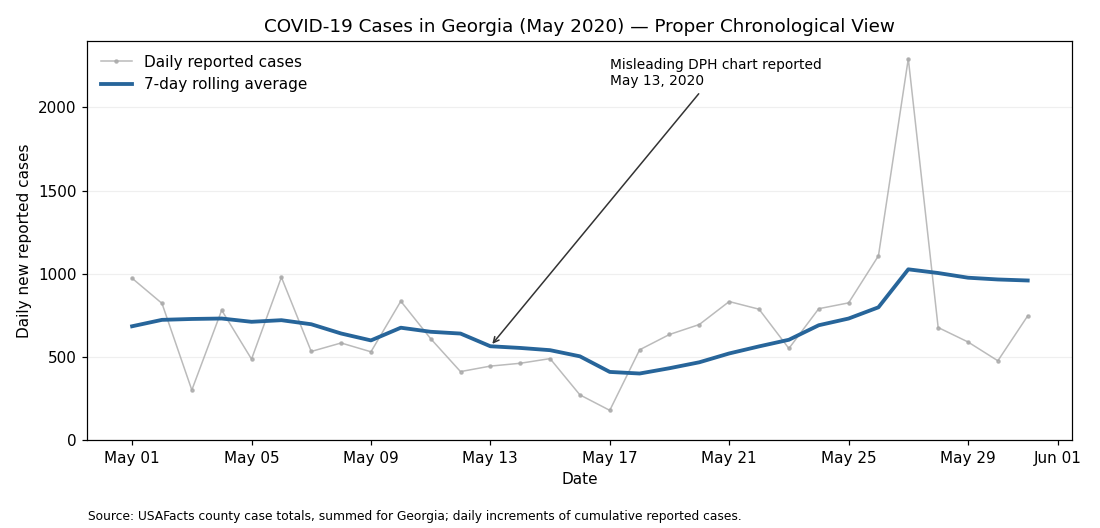

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(may["date"], may["daily_new_cases"], color="#aaa", alpha=0.8,
        marker="o", markersize=2, linewidth=1, label="Daily reported cases")
ax.plot(may["date"], may["rolling_7_days"], color="#27659a", linewidth=2.5,
        label="7-day rolling average")
event_date = pd.Timestamp("2020-05-13")
event_y = float(may.loc[may["date"] == event_date, "rolling_7_days"].iloc[0])
ax.annotate("Misleading DPH chart reported\nMay 13, 2020", xy=(event_date, event_y),
            xytext=(pd.Timestamp("2020-05-17"), may["daily_new_cases"].max() * 0.93),
            arrowprops={"arrowstyle": "->", "color": "#333"}, fontsize=9)
ax.set(title="COVID-19 Cases in Georgia (May 2020) — Proper Chronological View",
       xlabel="Date", ylabel="Daily new reported cases")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.set_ylim(bottom=min(0, may["daily_new_cases"].min()))
ax.grid(axis="y", alpha=0.2)
ax.legend(loc="upper left", frameon=False)
fig.text(0.08, 0.015, "Source: USAFacts county case totals, summed for Georgia; daily increments of cumulative reported cases.", fontsize=8)
fig.tight_layout(rect=[0, 0.045, 1, 1])
fig.savefig(OUT / "03_explanatory.png", dpi=140)
plt.show()
plt.close(fig)

## 6. Required critique and comparison

In [7]:
report = """# TP1 — Critique and redesign

## Part 1: Georgia DPH case study

The Columbia/Sabin Center account reports that a May 13, 2020 news report
identified a DPH graphic covering the five most affected Georgia counties.
Dates were arranged by case magnitude rather than time, with higher values
clustered on the left. This gave the visual impression of sustained decline.
The governor's spokesperson described an error and said it was corrected;
critics questioned intent. The visual distortion is demonstrable, but this
analysis does not treat intent as established.

**Perception:** viewers normally read a time axis from earlier to later.
Reordering dates breaks that expectation while retaining a familiar trend shape.
**Tufte's integrity principle:** even correct counts mislead when their positions
imply a relationship the data do not support. **Clarity and comparison:** an
irregular date sequence makes genuine changes over time difficult to compare.
**Context and storytelling:** a decline-shaped display can suggest improvement
relevant to reopening decisions, while omitting chronological fluctuations.
The axes, ordering, scope and source should support the message rather than
manufacture it. Smoothing must also be labeled so readers see what was derived.

Reference: [Columbia/Sabin Center case study](https://climate.law.columbia.edu/content/covid-19-data-misrepresented-georgia-health-department).
Its search-indexed text was available when the linked page returned 404.

## Part 2: Our three views

1. The exploratory line shows unmodified daily Georgia increments during May.
2. The educational recreation uses May 1–14, sorts counts descending and treats
   the resulting dates as categories. The apparent decline follows from sorting,
   not from a time trend. It is clearly labeled as an intentionally misleading
   exercise, not an authentic historical DPH image.
3. The explanatory view restores time order and shows raw data plus a trailing
   seven-day mean. The mean is calculated before filtering May so the first
   days have a complete history. The annotation marks **May 13 reporting of
   the controversy**, not an assumed exact original publication date.

The original graphic covered five counties; our assignment recreation uses
the Georgia statewide USAFacts series, including unallocated county cases.
It reproduces the ordering problem, not the exact original county values.
The USAFacts historical file contains later revisions and is not guaranteed
to equal the figures visible in the original May 2020 DPH snapshot.
Daily increments are net changes in reported cumulative totals; retrospective
corrections can produce negative values, which are not silently clipped.

Source: [USAFacts case CSV](https://static.usafacts.org/public/data/covid-19/covid_confirmed_usafacts.csv).
Assignment: https://github.com/ahmed3991/DataVisualisation-TP2025/blob/main/TP1/TP1.md
"""
(OUT / "REPORT.md").write_text(report, encoding="utf-8")
print("Saved all three required plots and the critique in", OUT)

Saved all three required plots and the critique in C:\Users\chikh\Desktop\UNIV\DataVisualisation-TP2025\DataVisualisation-TP2025--TP1\results


## Required written answers

In [8]:
from IPython.display import Markdown, display
display(Markdown((OUT / "REPORT.md").read_text(encoding="utf-8")))

# TP1 — Critique and redesign

## Part 1: Georgia DPH case study

The Columbia/Sabin Center account reports that a May 13, 2020 news report
identified a DPH graphic covering the five most affected Georgia counties.
Dates were arranged by case magnitude rather than time, with higher values
clustered on the left. This gave the visual impression of sustained decline.
The governor's spokesperson described an error and said it was corrected;
critics questioned intent. The visual distortion is demonstrable, but this
analysis does not treat intent as established.

**Perception:** viewers normally read a time axis from earlier to later.
Reordering dates breaks that expectation while retaining a familiar trend shape.
**Tufte's integrity principle:** even correct counts mislead when their positions
imply a relationship the data do not support. **Clarity and comparison:** an
irregular date sequence makes genuine changes over time difficult to compare.
**Context and storytelling:** a decline-shaped display can suggest improvement
relevant to reopening decisions, while omitting chronological fluctuations.
The axes, ordering, scope and source should support the message rather than
manufacture it. Smoothing must also be labeled so readers see what was derived.

Reference: [Columbia/Sabin Center case study](https://climate.law.columbia.edu/content/covid-19-data-misrepresented-georgia-health-department).
Its search-indexed text was available when the linked page returned 404.

## Part 2: Our three views

1. The exploratory line shows unmodified daily Georgia increments during May.
2. The educational recreation uses May 1–14, sorts counts descending and treats
   the resulting dates as categories. The apparent decline follows from sorting,
   not from a time trend. It is clearly labeled as an intentionally misleading
   exercise, not an authentic historical DPH image.
3. The explanatory view restores time order and shows raw data plus a trailing
   seven-day mean. The mean is calculated before filtering May so the first
   days have a complete history. The annotation marks **May 13 reporting of
   the controversy**, not an assumed exact original publication date.

The original graphic covered five counties; our assignment recreation uses
the Georgia statewide USAFacts series, including unallocated county cases.
It reproduces the ordering problem, not the exact original county values.
The USAFacts historical file contains later revisions and is not guaranteed
to equal the figures visible in the original May 2020 DPH snapshot.
Daily increments are net changes in reported cumulative totals; retrospective
corrections can produce negative values, which are not silently clipped.

Source: [USAFacts case CSV](https://static.usafacts.org/public/data/covid-19/covid_confirmed_usafacts.csv).
Assignment: https://github.com/ahmed3991/DataVisualisation-TP2025/blob/main/TP1/TP1.md
